# Clase 10 — Analizando el catálogo de Netflix

En este ejercicio asumirás el rol de un **Data Analyst** dentro de Netflix. El equipo de negocio quiere entender mejor cómo está distribuido el catálogo de la plataforma para tomar decisiones sobre futuras inversiones en contenido.

Para ello deberás utilizar las herramientas aprendidas en esta clase:

- `groupby()`
- funciones de agregación
- `agg()`
- `pivot_table()`
- `unstack()`
- gráficos con Pandas y Matplotlib

> No utilices bucles (`for`) para resolver los ejercicios.


## Parte 1: Exploración del dataset

Antes de comenzar el análisis responde:

1. Carga el dataset.
2. Muestra las primeras filas.
3. ¿Cuántas filas y columnas posee?
4. ¿Qué tipo de dato tiene cada columna?
5. ¿Existen valores nulos?
6. ¿Qué columnas presentan mayor cantidad de valores faltantes?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

df = pd.read_csv("netflix_data.csv")
display(df.head())
print(f"Dimensiones: {df.shape[0]} filas y {df.shape[1]} columnas")
display(df.dtypes.to_frame("tipo"))
nulos = df.isna().sum().sort_values(ascending=False)
print("Valores faltantes por columna:")
display(nulos[nulos > 0].to_frame("nulos"))

# Separamos coproducciones para atribuir cada título a todos sus países.
df_paises = (df.dropna(subset=["country"])
    .assign(country=lambda datos: datos["country"].str.split(","))
    .explode("country")
    .assign(country=lambda datos: datos["country"].str.strip()))
print(f"Registros país-título: {len(df_paises)}")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Dimensiones: 8807 filas y 12 columnas


,tipo
show_id,str
type,str
title,str
director,str
cast,str
country,str
date_added,str
release_year,int64
rating,str
duration,str


Valores faltantes por columna:


,nulos
director,2634
country,831
cast,825
date_added,10
rating,4
duration,3


Registros país-título: 10019


## Parte 2: Agrupaciones

### Ejercicio 1 - ¿Cuántos títulos existen por país?

Ordena el resultado de mayor a menor.


In [2]:
titulos_por_pais = df_paises.groupby("country")["show_id"].nunique().sort_values(ascending=False)
display(titulos_por_pais.to_frame("titulos"))

,titulos
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
...,...
Slovakia,1
Samoa,1
Sri Lanka,1


### Ejercicio 2 - ¿Cuántas películas y cuántas series tiene Netflix?

In [3]:
titulos_por_tipo = df.groupby("type")["show_id"].count().sort_values(ascending=False)
display(titulos_por_tipo.to_frame("titulos"))

,titulos
type,
Movie,6131
TV Show,2676


### Ejercicio 3 - ¿Cuántos títulos fueron lanzados cada año?

Ordena el resultado cronológicamente.


In [4]:
titulos_por_anio = df.groupby("release_year")["show_id"].count().sort_index()
display(titulos_por_anio.to_frame("titulos"))

,titulos
release_year,
1925,1
1942,2
1943,3
1944,3
1945,4
...,...
2017,1032
2018,1147
2019,1030


### Ejercicio 4 - ¿Cuál es la clasificación por edades más frecuente?

Por ejemplo:

- TV-MA
- TV-14
- PG
- R

In [5]:
clasificaciones = df.groupby("rating")["show_id"].count().sort_values(ascending=False)
display(clasificaciones.to_frame("titulos"))
print(f"Clasificación más frecuente: {clasificaciones.index[0]} ({clasificaciones.iloc[0]} títulos)")

,titulos
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


Clasificación más frecuente: TV-MA (3207 títulos)


### Ejercicio 5 - Obtén para cada tipo de contenido (Movie y TV Show):

- cantidad de títulos
- año promedio de lanzamiento
- año más reciente
- año más antiguo

> Utiliza **agg()**.

In [6]:
metricas_por_tipo = df.groupby("type").agg(
    cantidad_titulos=("show_id", "count"),
    anio_promedio=("release_year", "mean"),
    anio_mas_reciente=("release_year", "max"),
    anio_mas_antiguo=("release_year", "min"),
).round({"anio_promedio": 1})
display(metricas_por_tipo)

,cantidad_titulos,anio_promedio,anio_mas_reciente,anio_mas_antiguo
type,,,,
Movie,6131,2013.1,2021,1942
TV Show,2676,2016.6,2021,1925


## Parte 3: Agrupaciones múltiples

### Ejercicio 6 - Obtén la cantidad de títulos para cada combinación.

Agrupa por:

- país
- tipo de contenido

In [7]:
titulos_por_pais_tipo = (df_paises.groupby(["country", "type"])["show_id"]
    .nunique().sort_values(ascending=False))
display(titulos_por_pais_tipo.to_frame("titulos"))

,,titulos
country,type,
United States,Movie,2752
India,Movie,962
United States,TV Show,938
United Kingdom,Movie,534
Canada,Movie,319
...,...,...
Switzerland,TV Show,1
Ukraine,Movie,1
United Arab Emirates,TV Show,1


### Ejercicio 7 - Convierte el resultado anterior en una tabla donde:

- las filas sean los países
- las columnas sean Movie y TV Show

> Utiliza **unstack()**.

In [8]:
tabla_pais_tipo_unstack = titulos_por_pais_tipo.unstack()
display(tabla_pais_tipo_unstack)

type,Movie,TV Show
country,,
,6.0,1.0
Afghanistan,1.0,NaN
Albania,1.0,NaN
Algeria,3.0,NaN
Angola,1.0,NaN
...,...,...
Vatican City,1.0,NaN
Venezuela,4.0,NaN
Vietnam,7.0,NaN


## Parte 4: Tablas dinámicas

### Ejercicio 8 - Construye una tabla dinámica donde:

- filas → país
- columnas → tipo de contenido
- valores → cantidad de títulos

In [9]:
tabla_pais_tipo = df_paises.pivot_table(
    values="show_id", index="country", columns="type", aggfunc="nunique"
)
display(tabla_pais_tipo)

type,Movie,TV Show
country,,
,6.0,1.0
Afghanistan,1.0,NaN
Albania,1.0,NaN
Algeria,3.0,NaN
Angola,1.0,NaN
...,...,...
Vatican City,1.0,NaN
Venezuela,4.0,NaN
Vietnam,7.0,NaN


### Ejercicio 9 - Construye otra tabla dinámica donde:

- filas → clasificación por edades
- columnas → tipo de contenido
- valores → cantidad de títulos

In [10]:
tabla_rating_tipo = df.pivot_table(
    values="show_id", index="rating", columns="type", aggfunc="count"
)
display(tabla_rating_tipo)

type,Movie,TV Show
rating,,
66 min,1.0,NaN
74 min,1.0,NaN
84 min,1.0,NaN
G,41.0,NaN
NC-17,3.0,NaN
NR,75.0,5.0
PG,287.0,NaN
PG-13,490.0,NaN
R,797.0,2.0


### Ejercicio 10 - Modifica la tabla dinámica para que los valores faltantes aparezcan como **0**.

In [11]:
tabla_pais_tipo_completa = df_paises.pivot_table(
    values="show_id", index="country", columns="type",
    aggfunc="nunique", fill_value=0
)
display(tabla_pais_tipo_completa)

type,Movie,TV Show
country,,
,6,1
Afghanistan,1,0
Albania,1,0
Algeria,3,0
Angola,1,0
...,...,...
Vatican City,1,0
Venezuela,4,0
Vietnam,7,0


## Parte 5: Visualización

### Ejercicio 11 - Genera un gráfico de barras con el **Top 10 países con mayor cantidad de títulos**.

El gráfico debe incluir:

- título
- tamaño de figura
- etiquetas rotadas
- eje Y con nombre


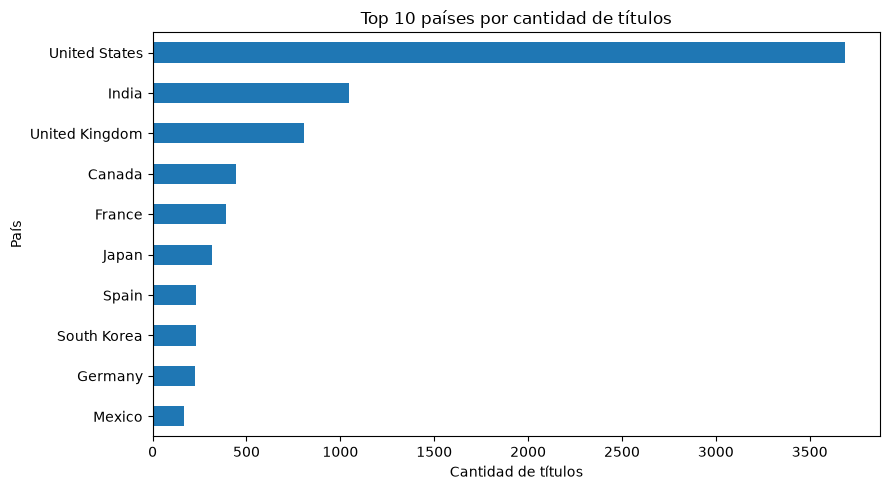

In [12]:
top10_paises = titulos_por_pais.head(10)
ax = top10_paises.sort_values().plot(
    kind="barh", figsize=(9, 5), title="Top 10 países por cantidad de títulos"
)
ax.set_xlabel("Cantidad de títulos")
ax.set_ylabel("País")
plt.tight_layout()
plt.show()

### Ejercicio 12 - Genera un gráfico de barras mostrando la cantidad de:

- Movies
- TV Shows

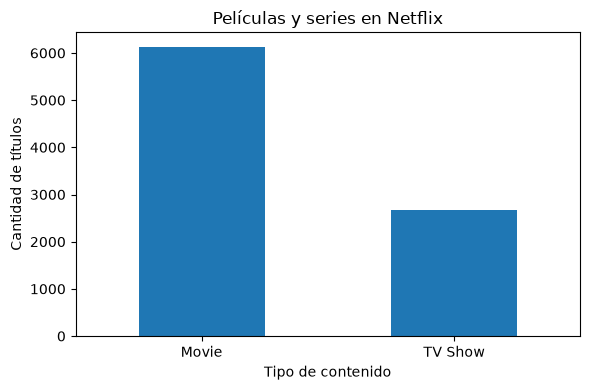

In [13]:
ax = titulos_por_tipo.plot(
    kind="bar", figsize=(6, 4), title="Películas y series en Netflix", rot=0
)
ax.set_xlabel("Tipo de contenido")
ax.set_ylabel("Cantidad de títulos")
plt.tight_layout()
plt.show()

### Ejercicio 13 - Utilizando la tabla dinámica, crea un gráfico de barras agrupadas que compare películas y series por país.


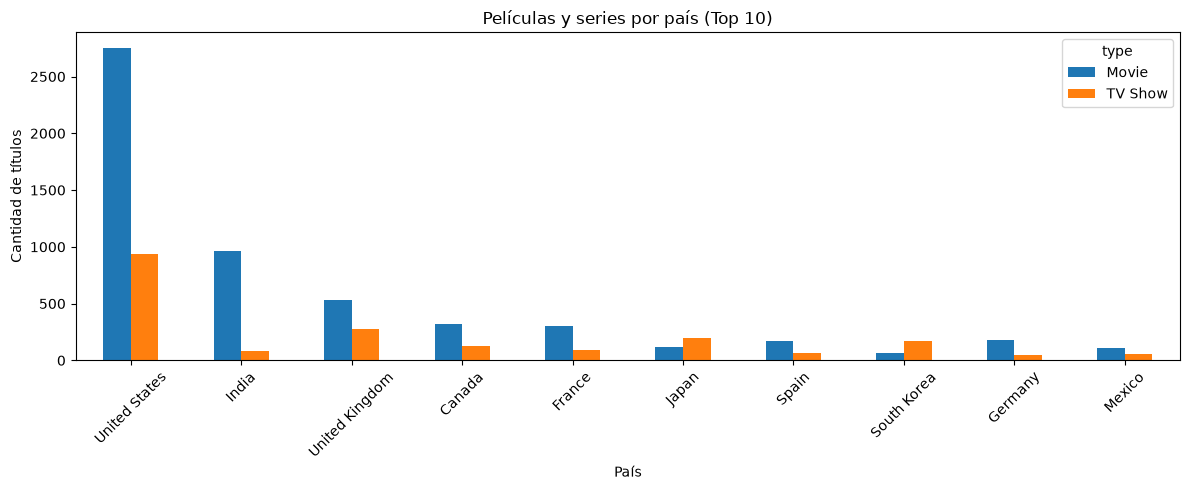

In [14]:
tabla_top10_paises = tabla_pais_tipo_completa.loc[top10_paises.index]
ax = tabla_top10_paises.plot(
    kind="bar", figsize=(12, 5), title="Películas y series por país (Top 10)"
)
ax.set_xlabel("País")
ax.set_ylabel("Cantidad de títulos")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## Parte 6: Análisis

Redacta al menos **cinco insights** basados en el análisis realizado. Algunas preguntas que puedes responder son:

- ¿Qué país domina el catálogo?
- ¿Netflix posee más películas o más series?
- ¿Qué clasificación por edades es la más utilizada?
- ¿Existen países donde predominen las series?
- ¿Qué tendencia observas respecto al año de lanzamiento de los contenidos?

Justifica cada respuesta utilizando los datos obtenidos.

In [15]:
pais_principal = titulos_por_pais.index[0]
tipo_principal = titulos_por_tipo.index[0]
etiqueta_tipo = {"Movie": "películas", "TV Show": "series"}[tipo_principal]
rating_principal = clasificaciones.index[0]
anio_pico = titulos_por_anio.idxmax()
titulos_recientes = df.loc[df["release_year"] >= 2016, "show_id"].count()
porcentaje_reciente = titulos_recientes / len(df) * 100
paises_mas_series = tabla_pais_tipo_completa.query("`TV Show` > Movie")
pais_series = (paises_mas_series["TV Show"] - paises_mas_series["Movie"]).idxmax()

print("INSIGHTS DEL CATÁLOGO")
print(f"1. {pais_principal} domina por atribución de país con {titulos_por_pais.iloc[0]} títulos; las coproducciones se cuentan en cada país participante.")
print(f"2. Predominan las {etiqueta_tipo}: {titulos_por_tipo.iloc[0]} de {len(df)} títulos ({titulos_por_tipo.iloc[0] / len(df) * 100:.1f}%).")
print(f"3. La clasificación más usada es {rating_principal}, con {clasificaciones.iloc[0]} títulos; es el segmento etario central del catálogo.")
print(f"4. {pais_series} es el país con mayor ventaja de series sobre películas, por lo que una estrategia local debe considerar formato episódico.")
print(f"5. El máximo de lanzamientos es {anio_pico}; además, {porcentaje_reciente:.1f}% del catálogo fue lanzado desde 2016, señal de un catálogo mayormente reciente.")

INSIGHTS DEL CATÁLOGO
1. United States domina por atribución de país con 3690 títulos; las coproducciones se cuentan en cada país participante.
2. Predominan las películas: 6131 de 8807 títulos (69.6%).
3. La clasificación más usada es TV-MA, con 3207 títulos; es el segmento etario central del catálogo.
4. South Korea es el país con mayor ventaja de series sobre películas, por lo que una estrategia local debe considerar formato episódico.
5. El máximo de lanzamientos es 2018; además, 64.2% del catálogo fue lanzado desde 2016, señal de un catálogo mayormente reciente.


## Desafío

Netflix desea aumentar su presencia en Latinoamérica. Analiza únicamente los siguientes países:

- Argentina
- Brasil
- Chile
- Colombia
- México
- Perú

Responde:

1. ¿Cuál aporta mayor cantidad de contenido?
2. ¿Predominan las películas o las series?
3. ¿Qué clasificación por edades es la más común?
4. Genera un gráfico comparativo.
5. Escribe una breve recomendación para el director regional de Netflix basada en tus resultados.


ANÁLISIS LATINOAMÉRICA


,titulos
country,
Mexico,169
Brazil,97
Argentina,91
Colombia,52
Chile,29
Peru,10


Mayor aporte: Mexico (169 títulos)
Tipo predominante: Movie (302 títulos)
Clasificación más común: TV-MA (286 títulos)


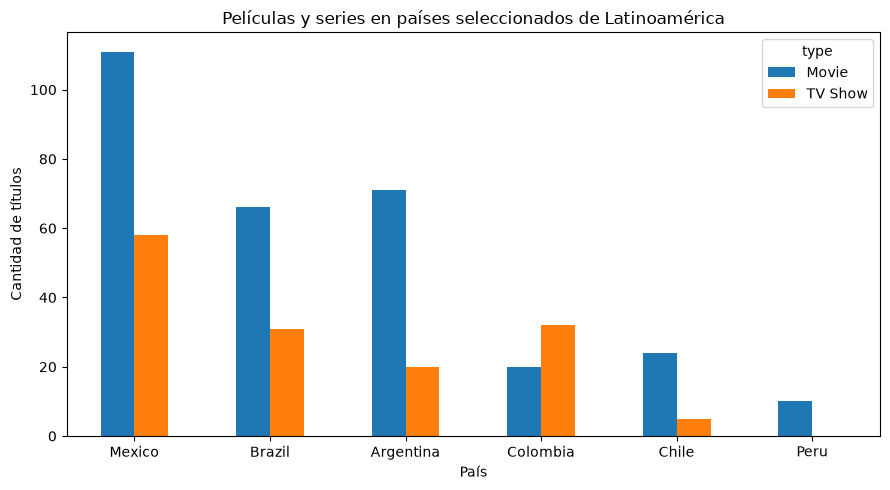

Recomendación: priorizar el país líder como mercado ancla y complementar la inversión regional con películas,
que predominan en los seis países analizados; segmentar la promoción según la clasificación más frecuente.


In [16]:
paises_latam = ["Argentina", "Brazil", "Chile", "Colombia", "Mexico", "Peru"]
df_latam = df_paises[df_paises["country"].isin(paises_latam)].copy()
titulos_latam = df_latam.groupby("country")["show_id"].nunique().sort_values(ascending=False)
tipos_latam = df_latam.groupby("type")["show_id"].count().sort_values(ascending=False)
rating_latam = df_latam.groupby("rating")["show_id"].count().sort_values(ascending=False)
tabla_latam = df_latam.pivot_table(
    values="show_id", index="country", columns="type", aggfunc="nunique", fill_value=0
)

print("ANÁLISIS LATINOAMÉRICA")
display(titulos_latam.to_frame("titulos"))
print(f"Mayor aporte: {titulos_latam.index[0]} ({titulos_latam.iloc[0]} títulos)")
print(f"Tipo predominante: {tipos_latam.index[0]} ({tipos_latam.iloc[0]} títulos)")
print(f"Clasificación más común: {rating_latam.index[0]} ({rating_latam.iloc[0]} títulos)")

ax = tabla_latam.loc[titulos_latam.index].plot(
    kind="bar", figsize=(9, 5), title="Películas y series en países seleccionados de Latinoamérica"
)
ax.set_xlabel("País")
ax.set_ylabel("Cantidad de títulos")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("Recomendación: priorizar el país líder como mercado ancla y complementar la inversión regional con películas,")
print("que predominan en los seis países analizados; segmentar la promoción según la clasificación más frecuente.")